Cell 1: Setup and Imports

In [1]:
# [Markdown]
# # FedShield: Dataset Exploration and Distribution Analysis
# This notebook analyzes the two highly imbalanced datasets used in the FedShield framework:
# 1. **Credit Card Fraud Detection** (Tabular, Binary Classification)
# 2. **DermaMNIST** (Image, Multi-class Classification)

# [Code]
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import medmnist
from medmnist import INFO

# Set visualization style
sns.set_theme(style="whitegrid")

Cell 2: Credit Card Dataset - Features & Distribution

--- Credit Card Dataset Overview ---
Total Samples: 284807
Total Features: 30 (excluding target class)

--- Feature Breakdown (X Variables) ---
1. Time: Seconds elapsed between this transaction and the first transaction.
2. Amount: Transaction amount.
3. V1 - V28: Principal Component Analysis (PCA) transformed features to protect user identity.

--- Class Distribution ---
Normal (0): 284315 samples (99.827%)
Fraud (1):  492 samples (0.173%)



C:\Users\HP\AppData\Local\Temp\ipykernel_12872\3948252685.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=['Normal (0)', 'Fraud (1)'], y=class_counts.values, palette=['#2ecc71', '#e74c3c'])


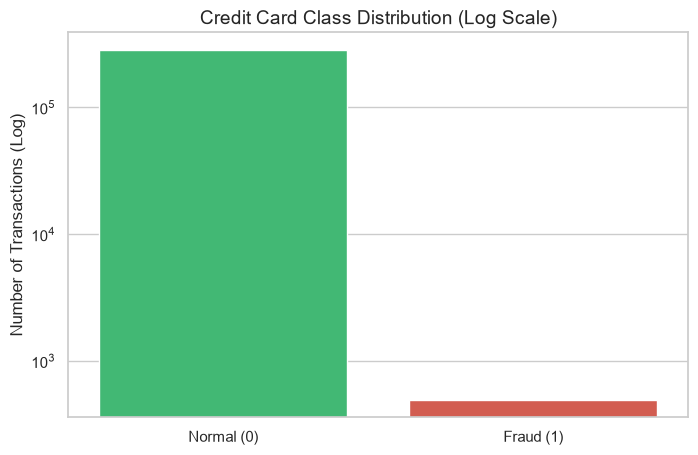

In [2]:
# [Markdown]
# ## 1. Credit Card Fraud Dataset (Tabular)
# This dataset contains transactions made by European cardholders in September 2013. 
# Due to confidentiality, original features are obfuscated using PCA (V1 to V28).

# [Code]
# Assuming the dataset is in the 'data' folder as per your .gitignore
try:
    df = pd.read_csv('data/creditcard.csv')
    
    print("--- Credit Card Dataset Overview ---")
    print(f"Total Samples: {len(df)}")
    print(f"Total Features: {df.shape[1] - 1} (excluding target class)\n")
    
    print("--- Feature Breakdown (X Variables) ---")
    print("1. Time: Seconds elapsed between this transaction and the first transaction.")
    print("2. Amount: Transaction amount.")
    print("3. V1 - V28: Principal Component Analysis (PCA) transformed features to protect user identity.\n")
    
    print("--- Class Distribution ---")
    class_counts = df['Class'].value_counts()
    normal_pct = (class_counts[0] / len(df)) * 100
    fraud_pct = (class_counts[1] / len(df)) * 100
    
    print(f"Normal (0): {class_counts[0]} samples ({normal_pct:.3f}%)")
    print(f"Fraud (1):  {class_counts[1]} samples ({fraud_pct:.3f}%)\n")
    
    # Plotting the extreme imbalance
    plt.figure(figsize=(8, 5))
    ax = sns.barplot(x=['Normal (0)', 'Fraud (1)'], y=class_counts.values, palette=['#2ecc71', '#e74c3c'])
    plt.yscale('log') # Log scale is necessary because fraud is so rare
    plt.title('Credit Card Class Distribution (Log Scale)', fontsize=14)
    plt.ylabel('Number of Transactions (Log)')
    plt.show()

except FileNotFoundError:
    print("Please ensure 'creditcard.csv' is placed inside the 'data/' directory.")

Cell 3: DermaMNIST Dataset - Metadata & Distribution

--- DermaMNIST Dataset Overview ---
Image Resolution: 28x28 RGB
Total Classes: 7
Total Training Samples: 7007

--- Class Dictionary ---
Class 0: actinic keratoses and intraepithelial carcinoma
Class 1: basal cell carcinoma
Class 2: benign keratosis-like lesions
Class 3: dermatofibroma
Class 4: melanoma
Class 5: melanocytic nevi
Class 6: vascular lesions

--- Class Distribution ---
actinic keratoses and intraepithelial carcinoma: 228 samples (3.25%)
basal cell carcinoma: 359 samples (5.12%)
benign keratosis-like lesions: 769 samples (10.97%)
dermatofibroma: 80 samples (1.14%)
melanoma: 779 samples (11.12%)
melanocytic nevi: 4693 samples (66.98%)
vascular lesions: 99 samples (1.41%)


C:\Users\HP\AppData\Local\Temp\ipykernel_12872\2307223786.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(class_names.values()), y=label_counts.values, palette="viridis")


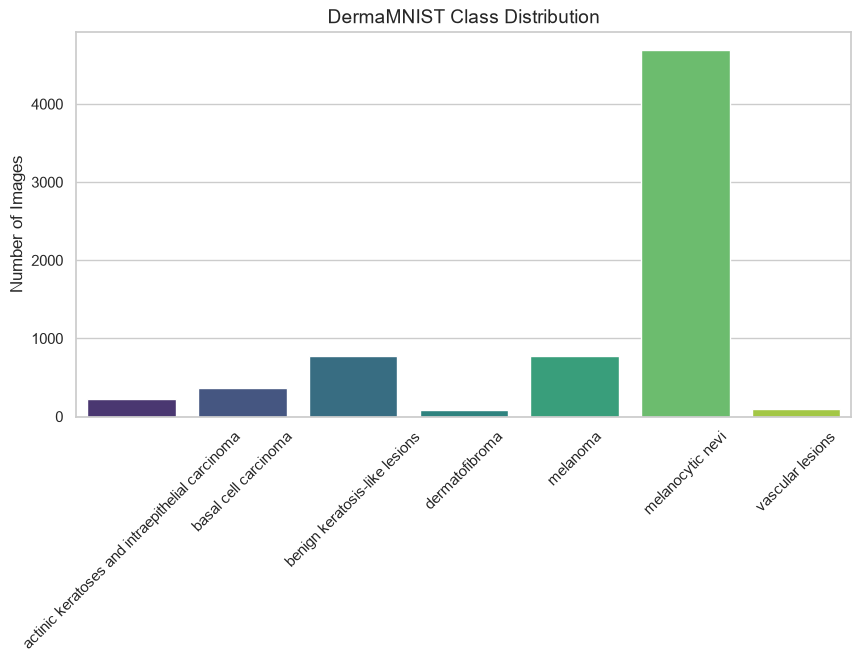

In [3]:
# [Markdown]
# ## 2. DermaMNIST Dataset (Medical Imaging)
# A subset of MedMNIST v2 based on the HAM10000 dataset. It contains 28x28 RGB images of 7 distinct skin diseases.

# [Code]
# Load DermaMNIST info
data_flag = 'dermamnist'
info = INFO[data_flag]
n_classes = len(info['label'])
DataClass = getattr(medmnist, info['python_class'])

# Download/Load the training split
train_dataset = DataClass(split='train', download=True)

print("--- DermaMNIST Dataset Overview ---")
print(f"Image Resolution: 28x28 RGB")
print(f"Total Classes: {n_classes}")
print(f"Total Training Samples: {len(train_dataset)}\n")

print("--- Class Dictionary ---")
class_names = info['label']
for key, desc in class_names.items():
    print(f"Class {key}: {desc}")

# Get class distribution
labels = [label[0] for _, label in train_dataset]
label_counts = pd.Series(labels).value_counts().sort_index()

print("\n--- Class Distribution ---")
for i, count in label_counts.items():
    print(f"{class_names[str(i)]}: {count} samples ({(count/len(labels))*100:.2f}%)")

# Plotting the multi-class imbalance
plt.figure(figsize=(10, 5))
sns.barplot(x=list(class_names.values()), y=label_counts.values, palette="viridis")
plt.title('DermaMNIST Class Distribution', fontsize=14)
plt.xticks(rotation=45)
plt.ylabel('Number of Images')
plt.show()

Cell 4: DermaMNIST - Visualizing the Skin Images

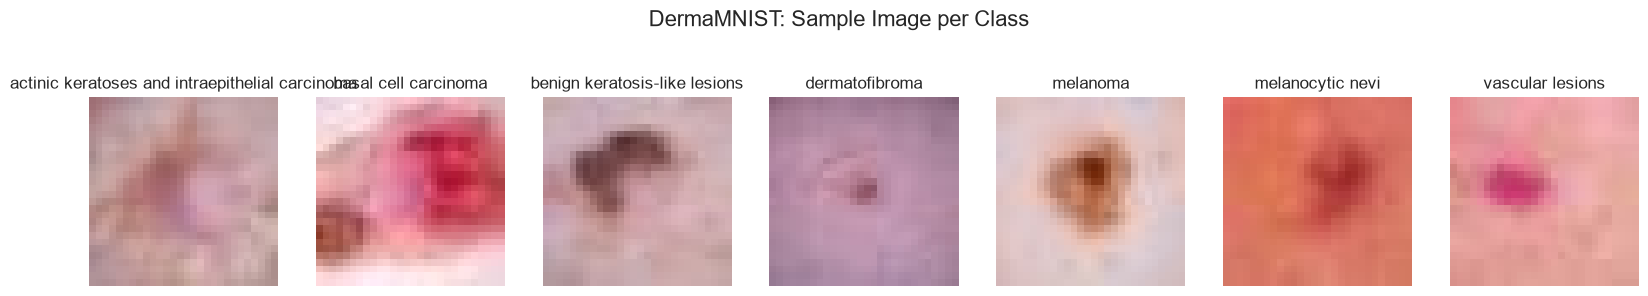

In [4]:
# [Markdown]
# ### Sample Images per Class
# Plotting a representative 28x28 RGB image for each of the 7 skin disease classes.

# [Code]
# Find one image index for each class
class_indices = {}
for idx, (_, label) in enumerate(train_dataset):
    lbl = label[0]
    if lbl not in class_indices:
        class_indices[lbl] = idx
    if len(class_indices) == n_classes:
        break

# Plot the images
fig, axes = plt.subplots(1, 7, figsize=(20, 3))
for i in range(n_classes):
    idx = class_indices[i]
    img, label = train_dataset[idx]
    
    axes[i].imshow(img)
    axes[i].set_title(class_names[str(i)], fontsize=12)
    axes[i].axis('off')

plt.suptitle("DermaMNIST: Sample Image per Class", fontsize=16, y=1.1)
plt.show()